# 09. Final Test Evaluation — Industrial Surface Defect Detection

**Purpose:** perform the final evaluation on the held-out test split after model selection and validation threshold tuning are complete.

## Important evaluation rules
- This notebook evaluates **one frozen model** on the test split.
- It reads the confidence and NMS thresholds selected in Notebook 08.
- Do not tune thresholds, anchors, model weights, or preprocessing using test results.
- The test set is used only for this final report.
- Confirm that Notebook 07/08 validation analysis is complete before running this notebook.

> **Preprocessing correction:** This notebook uses the exact MobileNetV2 `preprocess_input` transform used by Notebook 06 training. The earlier `/255.0` evaluation preprocessing did not match training and could suppress or distort predictions.

In [1]:

import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "src" / "data" / "dataset.py").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found. Open from project root or notebooks folder.")
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

DATASET_PATH = PROJECT_ROOT / "data" / "NEU-DET"
BASELINE_PATH = PROJECT_ROOT / "models" / "best_model.keras"
FOCAL_PATH = PROJECT_ROOT / "models" / "focal_experiment" / "best_model_focal.keras"
ANCHORS_PATH = PROJECT_ROOT / "models" / "anchors.npy"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

CLASS_NAMES = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]
NUM_CLASSES = len(CLASS_NAMES)
GRID_SIZE, NUM_ANCHORS, IMAGE_SIZE = 7, 5, 224

print("Project:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)



Project: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow
TensorFlow: 2.15.0


## 1. Select the final model (freeze this choice)

In [2]:

# Default: use Focal Loss if its checkpoint exists; otherwise use Baseline BCE.
# Change FINAL_MODEL_NAME only if you already selected another model using validation results.
available = {
    "Baseline_BCE": BASELINE_PATH.exists(),
    "Focal_Loss": FOCAL_PATH.exists()
}
print("Available checkpoints:", available)

FINAL_MODEL_NAME = "Focal_Loss" if available["Focal_Loss"] else "Baseline_BCE"

MODEL_PATHS = {
    "Baseline_BCE": BASELINE_PATH,
    "Focal_Loss": FOCAL_PATH
}
if not available.get(FINAL_MODEL_NAME, False):
    raise FileNotFoundError(f"Checkpoint missing for selected model: {FINAL_MODEL_NAME}")

SETTINGS_PATH = RESULTS_DIR / f"{FINAL_MODEL_NAME.lower()}_selected_validation_settings.json"
if not SETTINGS_PATH.exists():
    raise FileNotFoundError(
        f"Missing validation settings: {SETTINGS_PATH}. "
        "Run Notebook 08 for the selected model and save its settings before final test evaluation."
    )

with open(SETTINGS_PATH, "r", encoding="utf-8") as f:
    frozen_settings = json.load(f)

CONF_THRESHOLD = float(frozen_settings["confidence_threshold"])
NMS_IOU = float(frozen_settings["nms_iou_threshold"])
MATCH_IOU = float(frozen_settings.get("matching_iou_threshold", 0.50))

print("Final model:", FINAL_MODEL_NAME)
print("Model path:", MODEL_PATHS[FINAL_MODEL_NAME])
print("Frozen validation settings:", frozen_settings)


Available checkpoints: {'Baseline_BCE': True, 'Focal_Loss': True}
Final model: Focal_Loss
Model path: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\focal_experiment\best_model_focal.keras
Frozen validation settings: {'model': 'Focal_Loss', 'confidence_threshold': 0.6, 'nms_iou_threshold': 0.5, 'matching_iou_threshold': 0.5, 'data_split': 'validation', 'warning': 'Do not use these settings as final test results until frozen.'}


## 2. Load the test split, anchors and model

In [3]:

from src.data.dataset import get_dataset_splits

train_samples, val_samples, test_samples = get_dataset_splits(str(DATASET_PATH))
print(f"Train: {len(train_samples)} | Validation: {len(val_samples)} | Test: {len(test_samples)}")

if not ANCHORS_PATH.exists():
    raise FileNotFoundError(f"Missing anchors: {ANCHORS_PATH}")
anchors = np.load(ANCHORS_PATH).astype(np.float32)
if anchors.shape != (NUM_ANCHORS, 2):
    raise ValueError(f"Expected anchors shape (5,2), got {anchors.shape}")

model = tf.keras.models.load_model(MODEL_PATHS[FINAL_MODEL_NAME], compile=False)
print("Loaded model output shape:", model.output_shape)
if tuple(model.output_shape[1:]) != (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, 5+NUM_CLASSES):
    raise ValueError(f"Unexpected output shape: {model.output_shape}")
print("Anchors:\n", anchors)


Train: 1151 | Validation: 288 | Test: 360


Loaded model output shape: (None, 7, 7, 5, 11)
Anchors:
 [[0.1828321  0.24619976]
 [0.28540698 0.51598006]
 [0.21671906 0.910609  ]
 [0.6913246  0.32715988]
 [0.81677145 0.9229429 ]]


## 3. Confirm preprocessing and decoding

In [4]:

def load_image(image_path):
    """
    IMPORTANT: Match Notebook 06 training preprocessing exactly.
    MobileNetV2 preprocess_input maps RGB pixel values from [0, 255] to [-1, 1].
    Do NOT divide by 255 here.
    """
    image = Image.open(image_path).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    image = np.asarray(image, dtype=np.float32)  # keep [0, 255] before preprocessing
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image.astype(np.float32)

def box_iou_xyxy(a, b):
    ax1,ay1,ax2,ay2 = map(float,a)
    bx1,by1,bx2,by2 = map(float,b)
    ix1,iy1=max(ax1,bx1),max(ay1,by1)
    ix2,iy2=min(ax2,bx2),min(ay2,by2)
    inter=max(0,ix2-ix1)*max(0,iy2-iy1)
    area_a=max(0,ax2-ax1)*max(0,ay2-ay1)
    area_b=max(0,bx2-bx1)*max(0,by2-by1)
    return inter/(area_a+area_b-inter+1e-9)

def decode_predictions(raw, conf_threshold, nms_iou, max_detections=100):
    raw=np.asarray(raw)
    if raw.ndim==5: raw=raw[0]
    expected=(GRID_SIZE,GRID_SIZE,NUM_ANCHORS,5+NUM_CLASSES)
    if raw.shape!=expected:
        raise ValueError(f"Expected prediction shape {expected}, got {raw.shape}")
    candidates=[]
    for row in range(GRID_SIZE):
        for col in range(GRID_SIZE):
            for a in range(NUM_ANCHORS):
                pred=raw[row,col,a]
                tx,ty,tw,th=pred[:4]
                obj=1/(1+np.exp(-np.clip(float(pred[4]),-30,30)))
                logits=pred[5:]
                ex=np.exp(logits-np.max(logits))
                probs=ex/(np.sum(ex)+1e-9)
                cls=int(np.argmax(probs))
                score=float(obj*probs[cls])
                if score<conf_threshold: continue

                # Encoder uses direct within-cell tx/ty offsets (not sigmoid offsets).
                tx=float(np.clip(tx,0,1)); ty=float(np.clip(ty,0,1))
                cx=(col+tx)/GRID_SIZE; cy=(row+ty)/GRID_SIZE
                w=float(anchors[a,0]*np.exp(np.clip(tw,-5,5)))
                h=float(anchors[a,1]*np.exp(np.clip(th,-5,5)))
                box=[
                    float(np.clip(cx-w/2,0,1)),float(np.clip(cy-h/2,0,1)),
                    float(np.clip(cx+w/2,0,1)),float(np.clip(cy+h/2,0,1))
                ]
                if box[2]>box[0] and box[3]>box[1]:
                    candidates.append({"box":box,"score":score,"class_id":cls})

    kept=[]
    for cls in range(NUM_CLASSES):
        pending=sorted([d for d in candidates if d["class_id"]==cls],
                       key=lambda d:d["score"],reverse=True)
        while pending:
            best=pending.pop(0); kept.append(best)
            pending=[d for d in pending
                     if box_iou_xyxy(best["box"],d["box"])<nms_iou]
    return sorted(kept,key=lambda d:d["score"],reverse=True)[:max_detections]

def get_ground_truth(sample):
    boxes=np.asarray(sample["boxes"],dtype=np.float32).reshape(-1,4)
    labels=np.asarray(sample["labels"],dtype=np.int32).reshape(-1)
    return boxes,labels


## 4. Run final predictions on the test split

In [5]:

test_predictions=[]
for idx,sample in enumerate(test_samples):
    x=load_image(sample["image"])[None,...]
    raw=model.predict(x,verbose=0)
    detections=decode_predictions(raw,CONF_THRESHOLD,NMS_IOU,max_detections=100)
    test_predictions.append(detections)
    if (idx+1)%50==0 or idx+1==len(test_samples):
        print(f"Processed {idx+1}/{len(test_samples)} test images")

print("Test predictions completed.")
print("Average detections/image:",np.mean([len(x) for x in test_predictions]))
print("Maximum detections/image:",max([len(x) for x in test_predictions],default=0))


Processed 50/360 test images
Processed 100/360 test images
Processed 150/360 test images
Processed 200/360 test images
Processed 250/360 test images
Processed 300/360 test images
Processed 350/360 test images
Processed 360/360 test images
Test predictions completed.
Average detections/image: 2.702777777777778
Maximum detections/image: 20


## 5. Calculate final detection metrics

In [6]:

def evaluate_detection(predictions,samples,iou_threshold=0.50):
    tp=fp=fn=0
    per_class={c:{"TP":0,"FP":0,"FN":0} for c in range(NUM_CLASSES)}
    for sample,dets in zip(samples,predictions):
        gt_boxes,gt_labels=get_ground_truth(sample)
        used=set()
        for det in sorted(dets,key=lambda d:d["score"],reverse=True):
            cls=int(det["class_id"])
            candidates=[
                (j,box_iou_xyxy(det["box"],gt_boxes[j]))
                for j in range(len(gt_boxes))
                if j not in used and int(gt_labels[j])==cls
            ]
            best=max(candidates,key=lambda x:x[1],default=(-1,0.0))
            if best[0]>=0 and best[1]>=iou_threshold:
                tp+=1; per_class[cls]["TP"]+=1; used.add(best[0])
            else:
                fp+=1; per_class[cls]["FP"]+=1
        for j,cls in enumerate(gt_labels):
            if j not in used:
                fn+=1; per_class[int(cls)]["FN"]+=1

    precision=tp/(tp+fp+1e-9)
    recall=tp/(tp+fn+1e-9)
    f1=2*precision*recall/(precision+recall+1e-9)
    rows=[]
    for cls,v in per_class.items():
        p=v["TP"]/(v["TP"]+v["FP"]+1e-9)
        r=v["TP"]/(v["TP"]+v["FN"]+1e-9)
        f=2*p*r/(p+r+1e-9)
        rows.append({"class":CLASS_NAMES[cls],**v,"precision":p,"recall":r,"f1":f})
    overall={"TP":tp,"FP":fp,"FN":fn,"precision":precision,"recall":recall,"f1":f1}
    return overall,pd.DataFrame(rows)

overall_metrics,per_class_df=evaluate_detection(test_predictions,test_samples,MATCH_IOU)
print("FINAL TEST METRICS")
display(pd.DataFrame([overall_metrics]).round(4))
print("PER-CLASS TEST METRICS")
display(per_class_df.round(4))


FINAL TEST METRICS


,TP,FP,FN,precision,recall,f1
0,228,745,626,0.2343,0.267,0.2496


PER-CLASS TEST METRICS


,class,TP,FP,FN,precision,recall,f1
0,crazing,83,211,79,0.2823,0.5123,0.3640
1,inclusion,25,212,134,0.1055,0.1572,0.1263
2,patches,33,137,160,0.1941,0.1710,0.1818
3,pitted_surface,55,24,32,0.6962,0.6322,0.6627
4,rolled-in_scale,27,135,105,0.1667,0.2045,0.1837
5,scratches,5,26,116,0.1613,0.0413,0.0658


## 6. Calculate AP and mAP

In [7]:

def average_precision_for_class(predictions,samples,class_id,iou_threshold):
    total_gt=sum(int(np.sum(np.asarray(s["labels"])==class_id)) for s in samples)
    if total_gt==0: return np.nan
    ranked=[]
    for image_idx,dets in enumerate(predictions):
        for det in dets:
            if det["class_id"]==class_id:
                ranked.append((det["score"],image_idx,det["box"]))
    ranked.sort(key=lambda x:x[0],reverse=True)
    matched=[set() for _ in samples]
    gt_cache=[get_ground_truth(s) for s in samples]
    tp_flags=[]; fp_flags=[]
    for score,image_idx,box in ranked:
        gt_boxes,gt_labels=gt_cache[image_idx]
        candidates=[
            (j,box_iou_xyxy(box,gt_boxes[j]))
            for j in range(len(gt_boxes))
            if int(gt_labels[j])==class_id and j not in matched[image_idx]
        ]
        best=max(candidates,key=lambda x:x[1],default=(-1,0.0))
        if best[0]>=0 and best[1]>=iou_threshold:
            matched[image_idx].add(best[0]); tp_flags.append(1); fp_flags.append(0)
        else:
            tp_flags.append(0); fp_flags.append(1)
    if not tp_flags: return 0.0
    tp_cum=np.cumsum(tp_flags); fp_cum=np.cumsum(fp_flags)
    recalls=tp_cum/total_gt
    precisions=tp_cum/(tp_cum+fp_cum+1e-9)
    return float(np.mean([
        np.max(precisions[recalls>=r]) if np.any(recalls>=r) else 0.0
        for r in np.linspace(0,1,101)
    ]))

iou_thresholds=np.arange(0.50,0.96,0.05)
map_rows=[]
ap_class_rows=[]
for iou in iou_thresholds:
    aps=[]
    for cls in range(NUM_CLASSES):
        ap=average_precision_for_class(test_predictions,test_samples,cls,float(iou))
        aps.append(ap)
        if np.isclose(iou,0.50):
            ap_class_rows.append({"class":CLASS_NAMES[cls],"AP@0.50":ap})
    map_rows.append({"IoU":round(float(iou),2),"mAP":float(np.nanmean(aps))})

map_df=pd.DataFrame(map_rows)
ap_class_df=pd.DataFrame(ap_class_rows)
print("AP by class at IoU 0.50")
display(ap_class_df.round(4))
print("mAP across IoU thresholds")
display(map_df.round(4))
print("mAP@0.50:",round(float(map_df.iloc[0]["mAP"]),4))
print("mAP@0.50:0.95:",round(float(map_df["mAP"].mean()),4))


AP by class at IoU 0.50


,class,AP@0.50
0,crazing,0.2164
1,inclusion,0.0429
2,patches,0.0567
3,pitted_surface,0.6071
4,rolled-in_scale,0.0511
5,scratches,0.0127


mAP across IoU thresholds


,IoU,mAP
0,0.50,0.1645
1,0.55,0.1400
2,0.60,0.1065
3,0.65,0.0666
4,0.70,0.0356
5,0.75,0.0180
6,0.80,0.0088
7,0.85,0.0058
8,0.90,0.0001
9,0.95,0.0000


mAP@0.50: 0.1645
mAP@0.50:0.95: 0.0546


## 7. Visualize test predictions

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.46666664..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.46666664..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.69411767..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.69411767..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.54509807..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.54509807..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5686275..1.0].
Clipping input data t

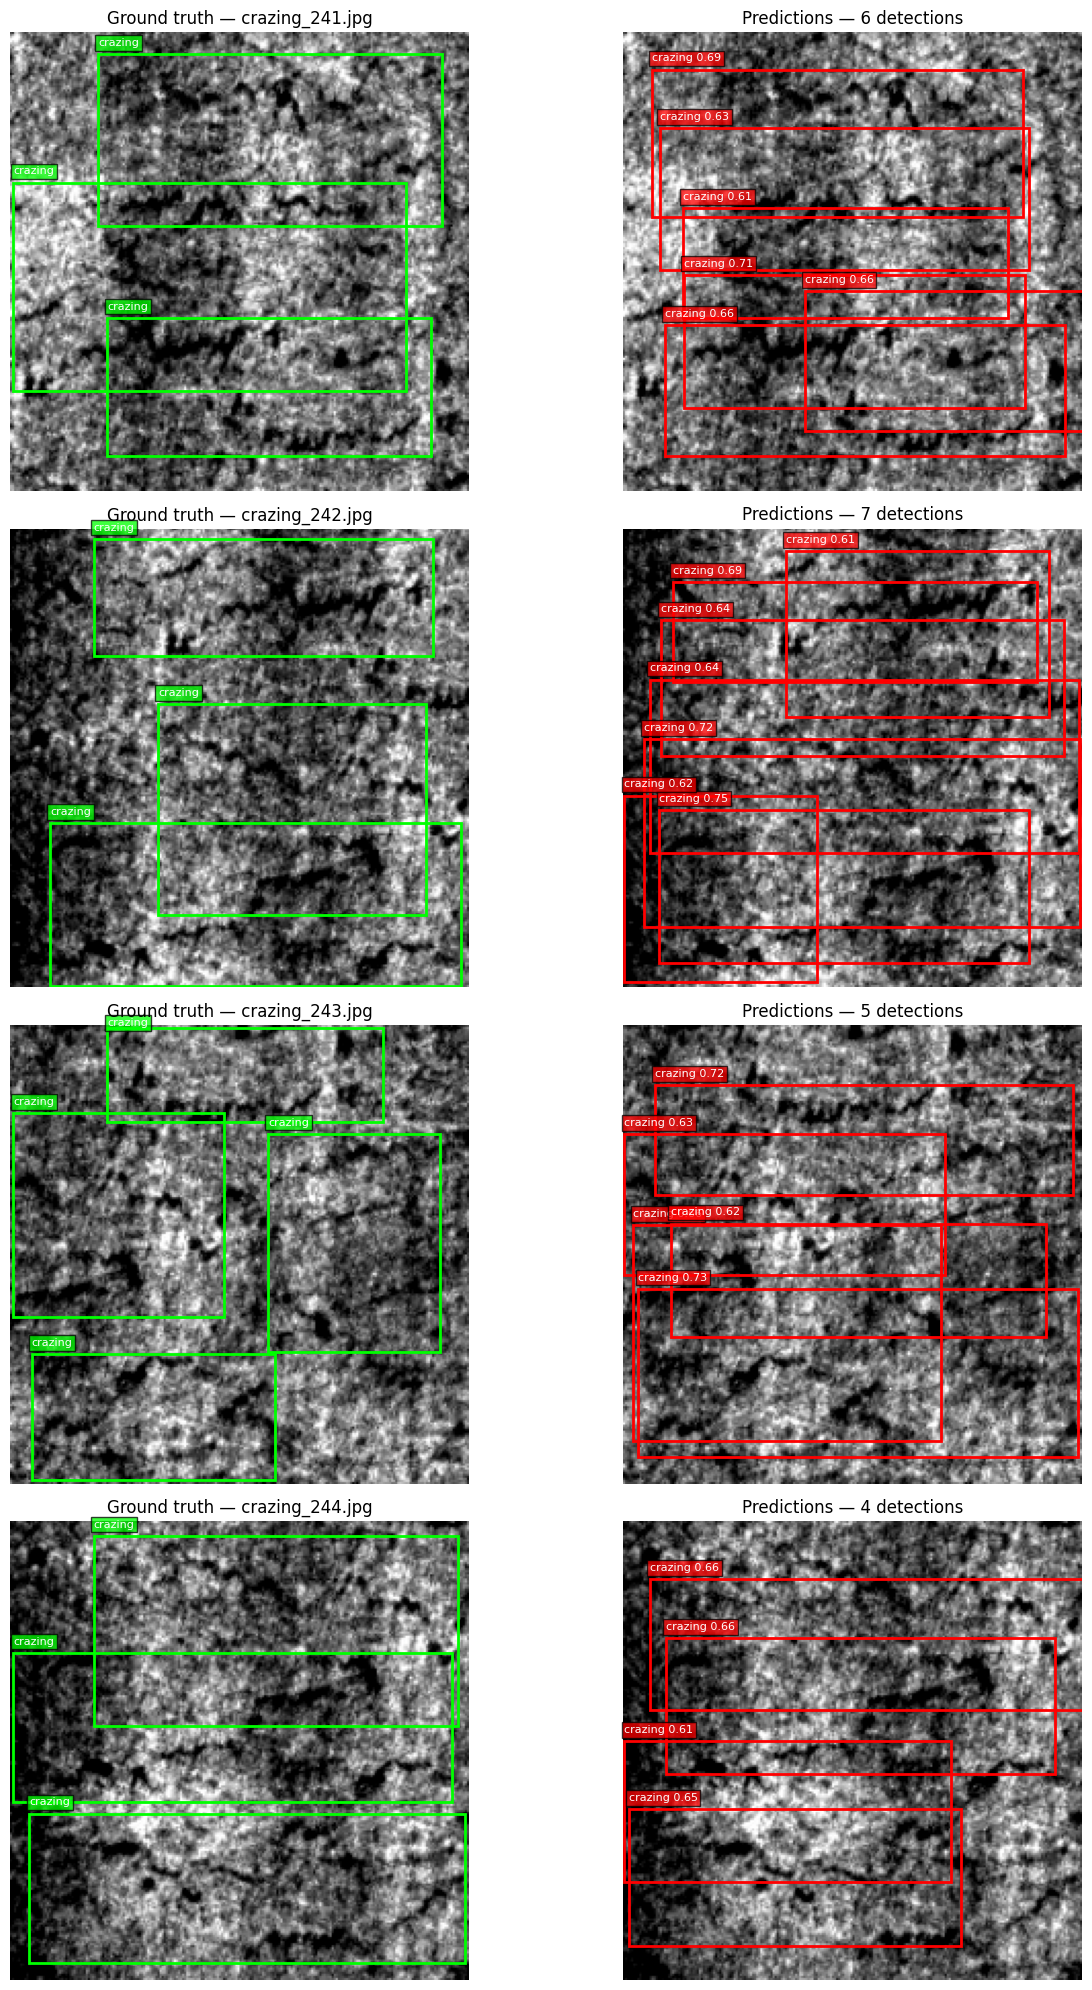

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.90588236..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.90588236..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.60784316..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.60784316..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.6784314..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.6784314..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.7176471..1.0].
Clipping input data to 

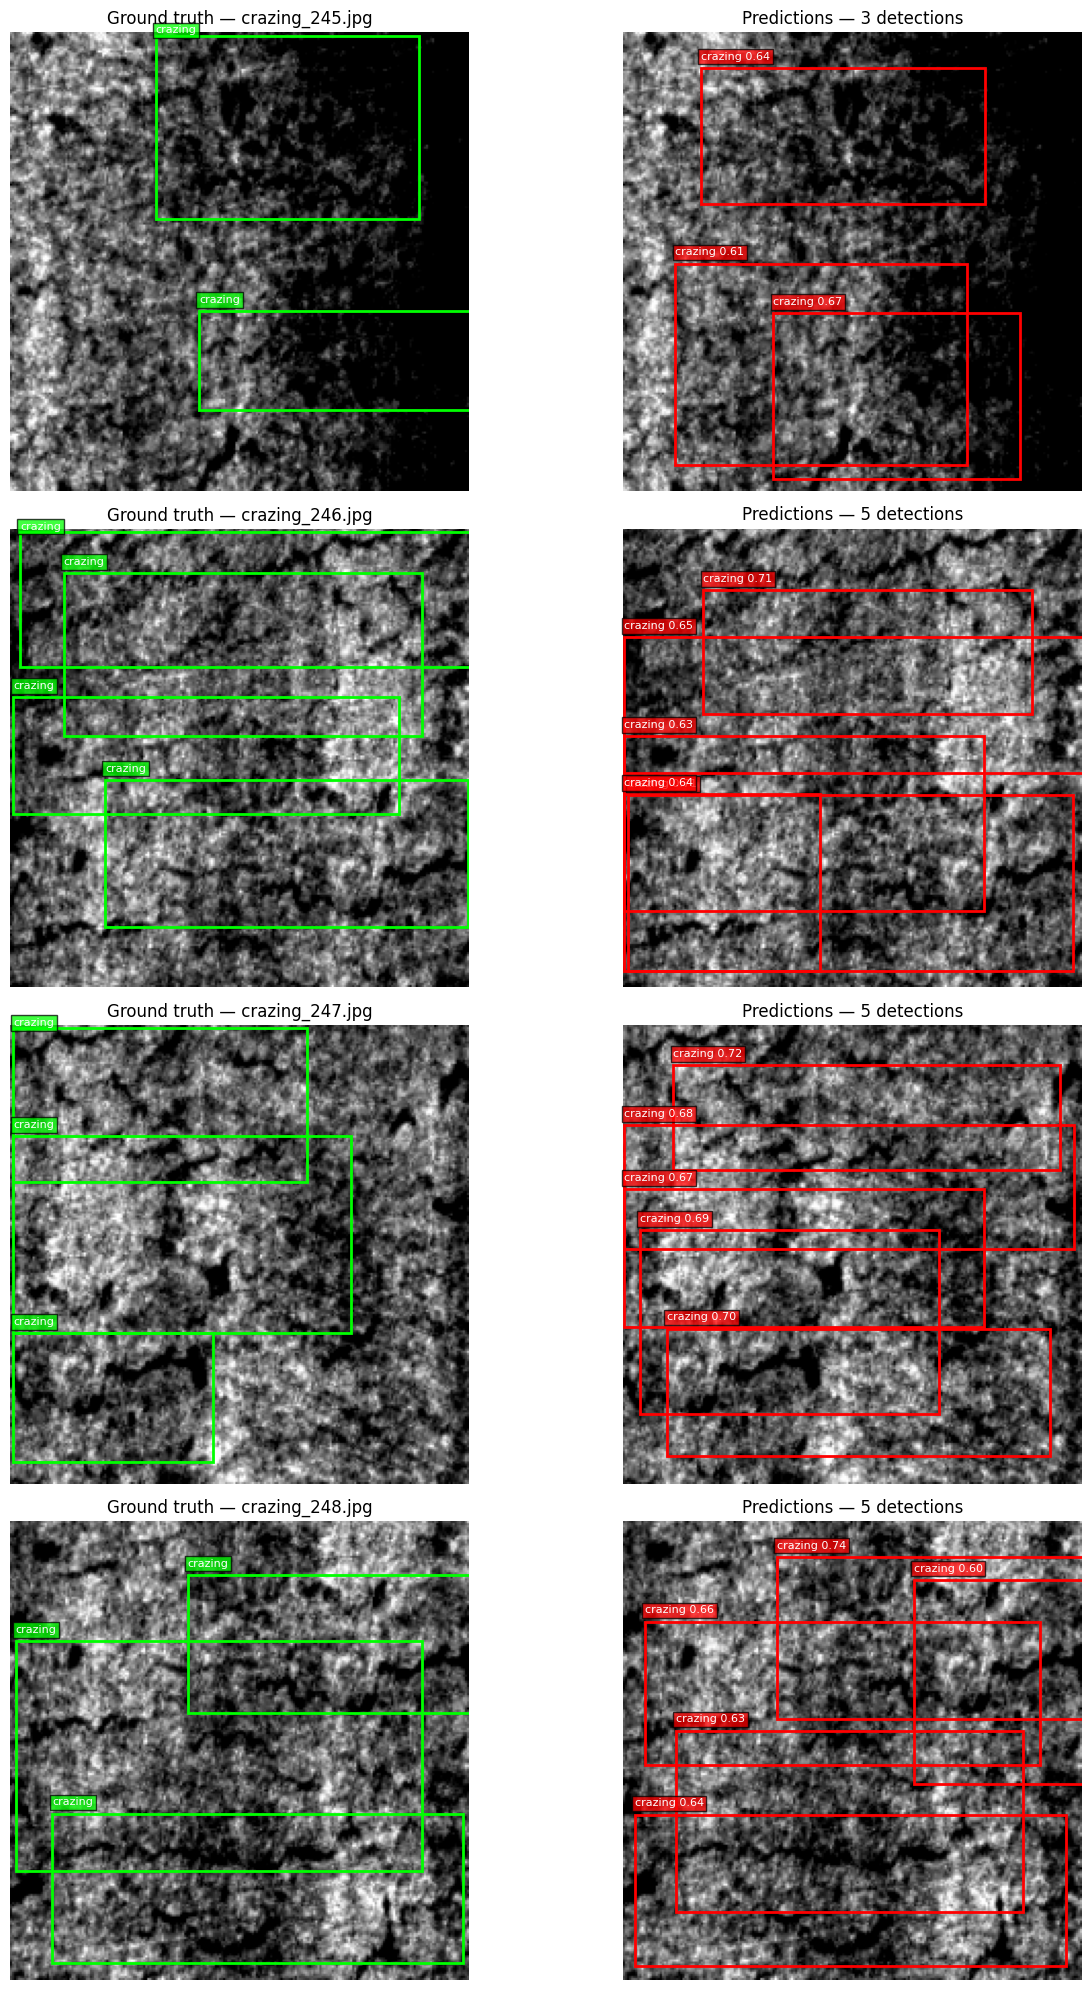

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5372549..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5372549..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.69411767..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.69411767..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.85882354..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.85882354..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5372549..1.0].
Clipping input data to 

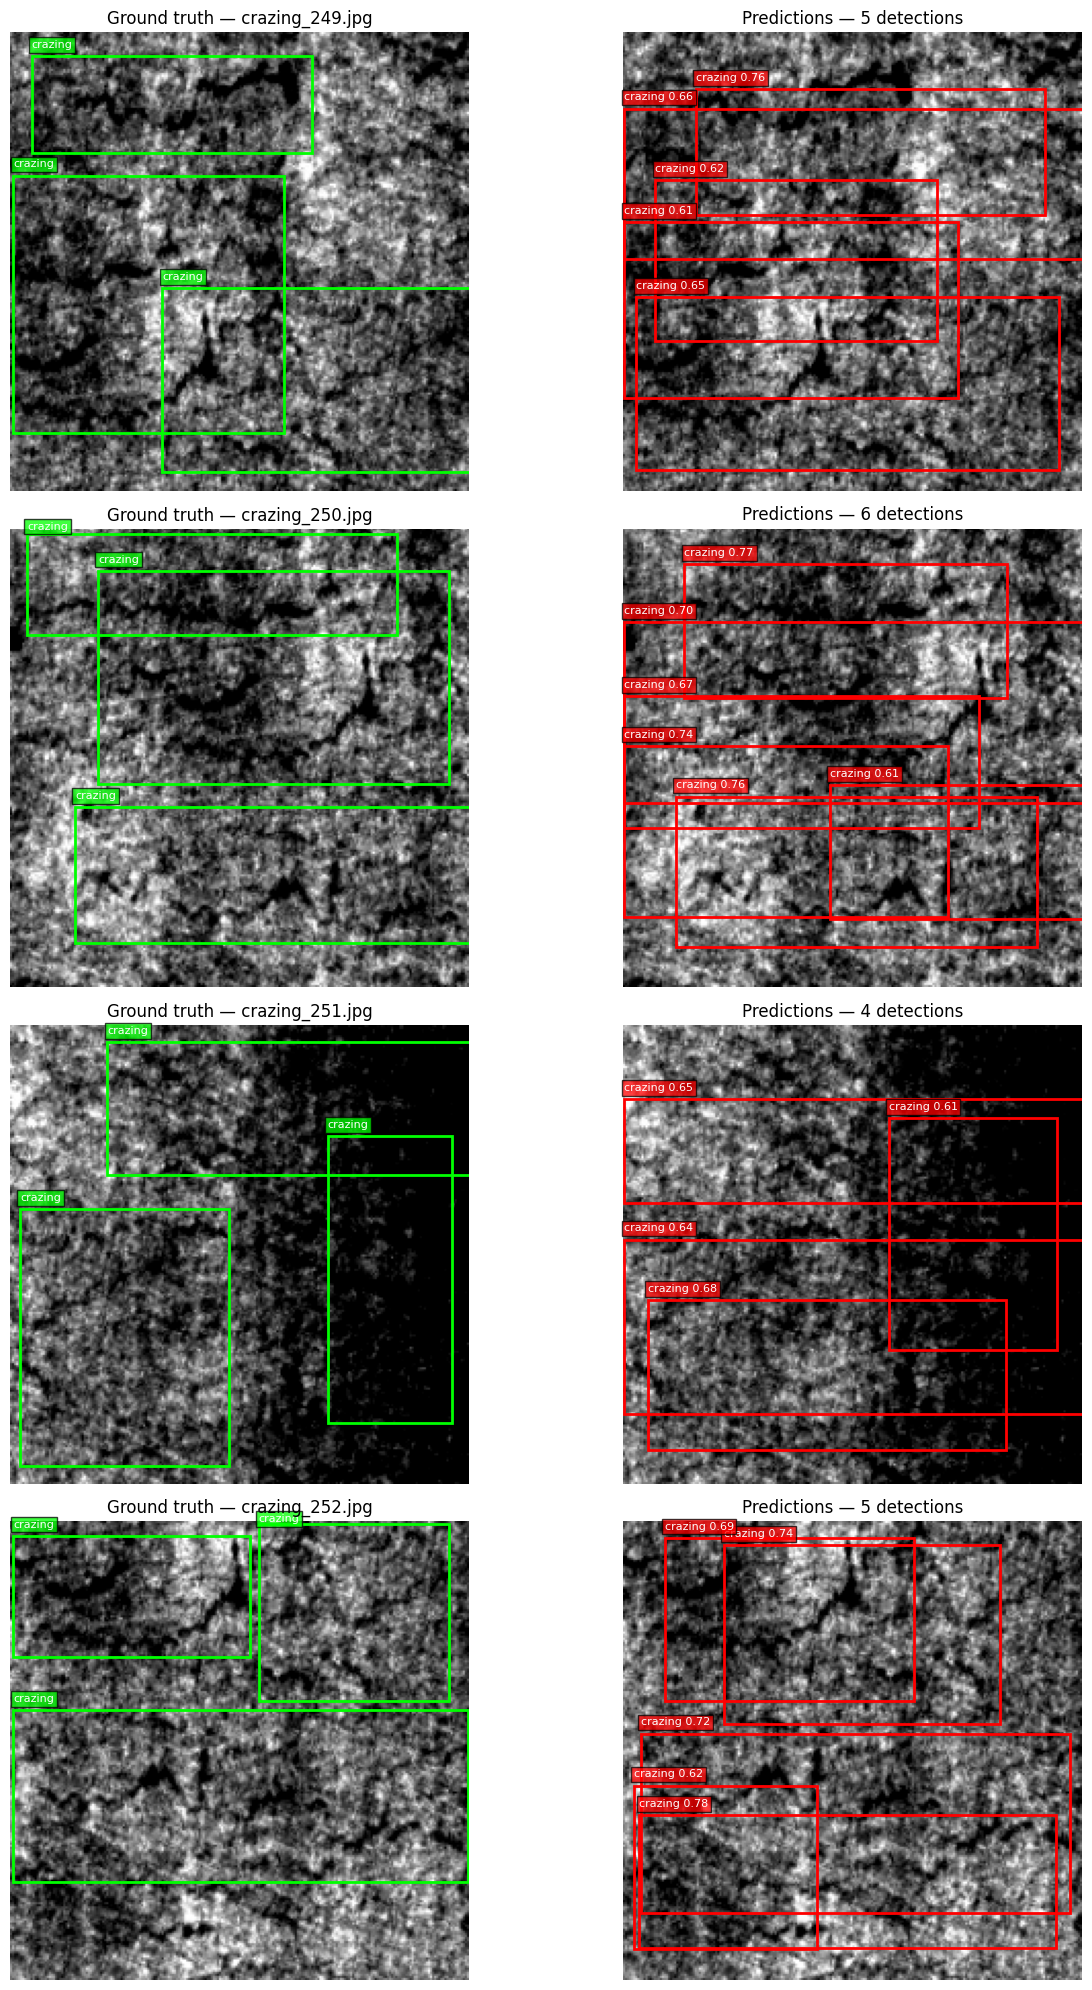

In [8]:

def draw_boxes(ax,image,boxes,labels,color,title,scores=None):
    ax.imshow(image); h,w=image.shape[:2]
    for i,(box,label) in enumerate(zip(boxes,labels)):
        x1,y1,x2,y2=box
        rect=plt.Rectangle((x1*w,y1*h),(x2-x1)*w,(y2-y1)*h,
                           fill=False,edgecolor=color,linewidth=2)
        ax.add_patch(rect)
        txt=CLASS_NAMES[int(label)]
        if scores is not None: txt+=f" {scores[i]:.2f}"
        ax.text(x1*w,max(0,y1*h-4),txt,color="white",fontsize=8,
                bbox=dict(facecolor=color,alpha=.75,pad=2))
    ax.set_title(title); ax.axis("off")

N_SHOW=min(12,len(test_samples))
for start in range(0,N_SHOW,4):
    fig,axes=plt.subplots(4,2,figsize=(14,20))
    for off in range(4):
        idx=start+off
        if idx>=N_SHOW:
            axes[off,0].axis("off"); axes[off,1].axis("off"); continue
        sample=test_samples[idx]
        image=load_image(sample["image"])
        gt_boxes,gt_labels=get_ground_truth(sample)
        dets=test_predictions[idx]
        draw_boxes(axes[off,0],image,gt_boxes,gt_labels,"lime",
                   f"Ground truth — {Path(sample['image']).name}")
        draw_boxes(axes[off,1],image,[d["box"] for d in dets],
                   [d["class_id"] for d in dets],"red",
                   f"Predictions — {len(dets)} detections",
                   [d["score"] for d in dets])
    plt.tight_layout(); plt.show()


## 8. Save final test report

In [9]:

final_summary={
    "model":FINAL_MODEL_NAME,
    "test_images":len(test_samples),
    "confidence_threshold":CONF_THRESHOLD,
    "nms_iou_threshold":NMS_IOU,
    "matching_iou_threshold":MATCH_IOU,
    **overall_metrics,
    "mAP@0.50":float(map_df.iloc[0]["mAP"]),
    "mAP@0.50:0.95":float(map_df["mAP"].mean()),
    "average_detections_per_image":float(np.mean([len(x) for x in test_predictions]))
}
summary_file=RESULTS_DIR/"final_test_summary.json"
per_class_file=RESULTS_DIR/"final_test_per_class.csv"
map_file=RESULTS_DIR/"final_test_map.csv"
with open(summary_file,"w",encoding="utf-8") as f:
    json.dump(final_summary,f,indent=2)
per_class_df.to_csv(per_class_file,index=False)
map_df.to_csv(map_file,index=False)

print("Saved final test report:")
print(summary_file)
print(per_class_file)
print(map_file)
display(pd.DataFrame([final_summary]).round(4))


Saved final test report:
d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\final_test_summary.json
d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\final_test_per_class.csv
d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\final_test_map.csv


,model,test_images,confidence_threshold,nms_iou_threshold,matching_iou_threshold,TP,FP,FN,precision,recall,f1,mAP@0.50,mAP@0.50:0.95,average_detections_per_image
0,Focal_Loss,360,0.6,0.5,0.5,228,745,626,0.2343,0.267,0.2496,0.1645,0.0546,2.7028


## 9. Final reporting guidance

When reporting results, include:
- Dataset and test split size.
- Selected model checkpoint.
- Frozen confidence and NMS thresholds selected on validation.
- Precision, Recall, F1, AP@0.50, mAP@0.50:0.95.
- Per-class results and example prediction visualizations.

**Do not claim the model is production-ready based only on this evaluation.** Discuss false positives, missed defects, class-level weaknesses, dataset limitations, and the need for testing on real production images.

The AP/mAP implementation here uses class-aware greedy matching and 101-point interpolated AP. For formal benchmarking or publication, cross-check with a recognized VOC/COCO evaluation package.